In [1]:
import random
from pathlib import Path
from PIL import Image

SRC_DIR = Path("../data/FullIJCNN2013")
OUT_DIR = Path("../data/yolo_dataset")

IMG_W, IMG_H = 1360, 800
SEED = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
print((SRC_DIR / "gt.txt").exists())

True


GOAL : put every important setting at the top so nothing important is buried inside of the actual middle code 

In [2]:
boxes_per_image = {}

with open(SRC_DIR / "gt.txt") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue

        filename, x1, y1, x2, y2, class_id = line.split(";")
        box = (int(x1), int(y1), int(x2), int(y2))

        if filename not in boxes_per_image:
            boxes_per_image[filename] = []
        boxes_per_image[filename].append(box)

a dictionary where each filename maps to the list of all its boxes

In [3]:
print(len(boxes_per_image))
print(sum(len(boxes) for boxes in boxes_per_image.values()))
print(boxes_per_image["00001.ppm"])

741
1213
[(983, 388, 1024, 432), (386, 494, 442, 552), (973, 335, 1031, 390)]


In [4]:
all_images = sorted(p.name for p in SRC_DIR.glob("*.ppm"))
signed = [name for name in all_images if name in boxes_per_image]
background = [name for name in all_images if name not in boxes_per_image]
rng = random.Random(SEED)
rng.shuffle(signed)
rng.shuffle(background)
def split_list(items):
    n = len(items)
    n_train = int(n * TRAIN_RATIO)
    n_val = int(n * VAL_RATIO)
    train = items[:n_train]
    val = items[n_train:n_train + n_val]
    test = items[n_train + n_val:]
    return train, val, test

signed_train, signed_val, signed_test = split_list(signed)
bg_train, bg_val, bg_test = split_list(background)

splits = {
    "train": signed_train + bg_train,
    "val": signed_val + bg_val,
    "test": signed_test + bg_test,
}

split all 900 images 70/15/15, with signed images and background images split separately, so each group keeps about 18% background. The split must be the same every time.

In [5]:
print(len(all_images), len(signed), len(background))

for name, images in splits.items():
    n_bg = sum(1 for img in images if img not in boxes_per_image)
    print(f"{name}: {len(images)} images, {n_bg} background ({n_bg / len(images):.1%})")

print(set(splits["train"]) & set(splits["val"]))
print(set(splits["train"]) & set(splits["test"]))
print(set(splits["val"]) & set(splits["test"]))

900 741 159
train: 629 images, 111 background (17.6%)
val: 134 images, 23 background (17.2%)
test: 137 images, 25 background (18.2%)
set()
set()
set()


In [7]:
def to_yolo_line(box):
    x1, y1, x2, y2 = box
    x_center = (x1 + x2) / 2 / IMG_W
    y_center = (y1 + y2) / 2 / IMG_H
    width = (x2 - x1) / IMG_W
    height = (y2 - y1) / IMG_H
    return f"0 {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}"

In [8]:
print(to_yolo_line((774, 411, 815, 446)))

0 0.584191 0.535625 0.030147 0.043750


**CHECKPOINT**

In [9]:
import shutil

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)

for split in splits:
    (OUT_DIR / "images" / split).mkdir(parents=True)
    (OUT_DIR / "labels" / split).mkdir(parents=True)

In [10]:
for split, images in splits.items():
    print(f"Converting {split}: {len(images)} images...")
    for name in images:
        stem = Path(name).stem

        with Image.open(SRC_DIR / name) as img:
            if img.size != (IMG_W, IMG_H):
                raise ValueError(f"{name} has size {img.size}, expected {(IMG_W, IMG_H)}")
            img.save(OUT_DIR / "images" / split / f"{stem}.png")

        boxes = boxes_per_image.get(name, [])
        lines = [to_yolo_line(box) for box in boxes]
        label_path = OUT_DIR / "labels" / split / f"{stem}.txt"
        label_path.write_text("\n".join(lines))

print("Done")

Converting train: 629 images...
Converting val: 134 images...
Converting test: 137 images...
Done


In [11]:
for split in splits:
    n_img = len(list((OUT_DIR / "images" / split).glob("*.png")))
    n_lbl = len(list((OUT_DIR / "labels" / split).glob("*.txt")))
    print(f"{split}: {n_img} images, {n_lbl} labels")

label_00001 = list(OUT_DIR.glob("labels/*/00001.txt"))[0]
print(label_00001)
print(label_00001.read_text())

train: 629 images, 629 labels
val: 134 images, 134 labels
test: 137 images, 137 labels
..\data\yolo_dataset\labels\train\00001.txt
0 0.737868 0.512500 0.030147 0.055000
0 0.304412 0.653750 0.041176 0.072500
0 0.736765 0.453125 0.042647 0.068750


In [12]:
yaml_text = """path: /content/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: sign
"""

(OUT_DIR / "data.yaml").write_text(yaml_text)
print((OUT_DIR / "data.yaml").read_text())

path: /content/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: sign



In [14]:
n_boxes = 0
n_empty = 0

for label_file in OUT_DIR.glob("labels/*/*.txt"):
    lines = label_file.read_text().splitlines()
    if not lines:
        n_empty += 1
    for line in lines:
        parts = line.split()
        assert len(parts) == 5, f"{label_file}: wrong number of values"
        assert parts[0] == "0", f"{label_file}: class is not 0"
        values = [float(v) for v in parts[1:]]
        assert all(0 < v < 1 for v in values), f"{label_file}: value outside 0-1"
        n_boxes += 1

assert n_boxes == 1213, f"Expected 1213 boxes, found {n_boxes}"
assert n_empty == 159, f"Expected 159 empty labels, found {n_empty}"

for split in splits:
    img_stems = {p.stem for p in (OUT_DIR / "images" / split).glob("*.png")}
    lbl_stems = {p.stem for p in (OUT_DIR / "labels" / split).glob("*.txt")}
    assert img_stems == lbl_stems, f"{split}: image and label names don't match"

print("All final checks passed")

All final checks passed


**Final sanity checks on files Yolo will use

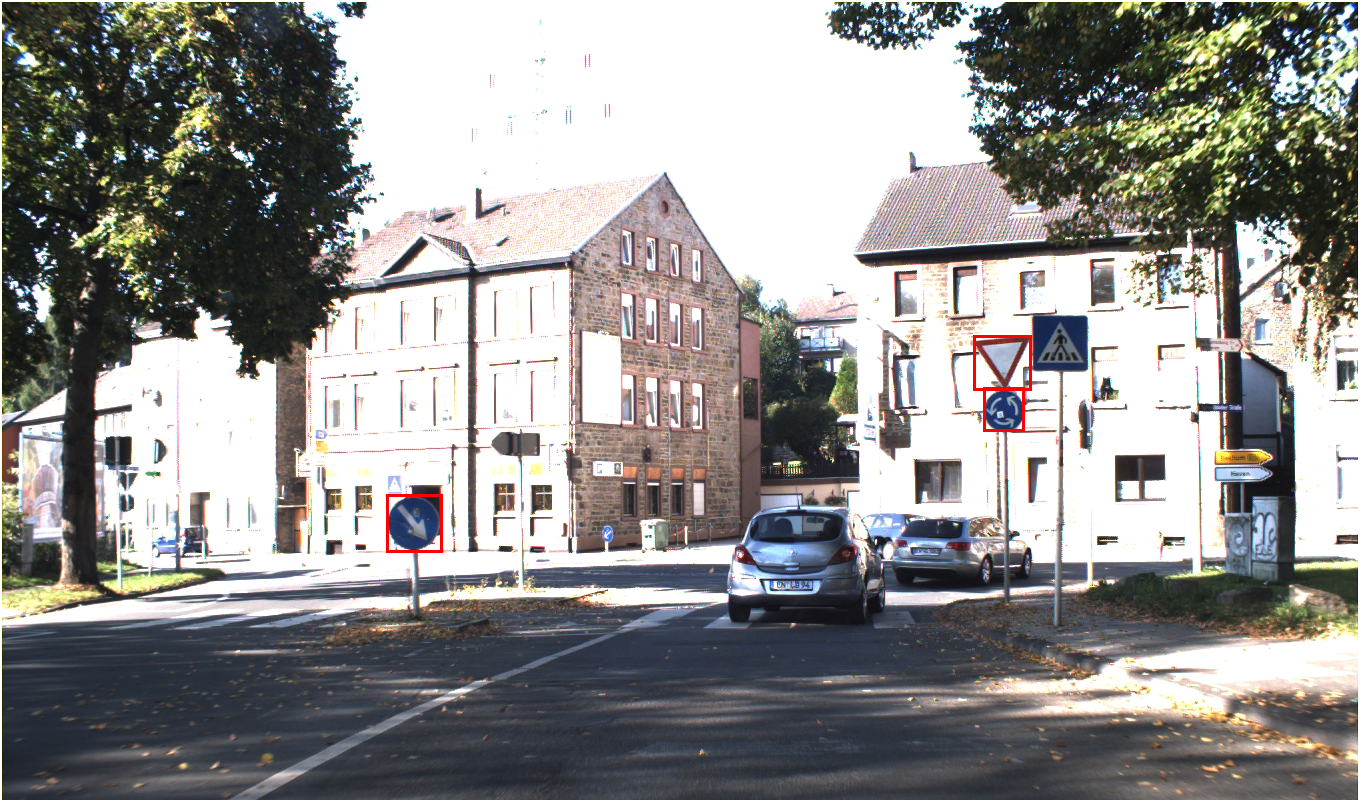

In [15]:
from PIL import ImageDraw

with Image.open(OUT_DIR / "images" / "train" / "00001.png") as img:
    img = img.convert("RGB")

draw = ImageDraw.Draw(img)
for line in (OUT_DIR / "labels" / "train" / "00001.txt").read_text().splitlines():
    _, xc, yc, w, h = line.split()
    xc, w = float(xc) * IMG_W, float(w) * IMG_W
    yc, h = float(yc) * IMG_H, float(h) * IMG_H
    draw.rectangle((xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2), outline="red", width=3)

img